# Инициализация

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
from sklearn.model_selection import StratifiedGroupKFold

In [2]:
data = pd.read_csv('../data/raw/asteroids.csv')

# Исследование исходного датасета

### Датасет содержит поля:
- **id** - уникальный идентификатор объекта в базе данных
- **name** - название астероида (постоянное или временное)
- **est_diameter_min** - минимальный предполагаемый диаметр объекта (в километрах)
- **est_diameter_max** - максимальный предполагаемый диаметр объекта (в километрах)
- **relative_velocity** - скорость движения астероида относительно Земли на момент сближения (в км/ч)
- **miss_distance** - дистанция пролета, т.е. минимальное расстояние от Земли (в километрах)
- **absolute_magnitude** - абсолютная звездная величина
- **hazardous** - опасность объекта в формате True/False


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90266 non-null  float64
 1   name                90790 non-null  str    
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90379 non-null  float64
 4   relative_velocity   90279 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   absolute_magnitude  90152 non-null  float64
 7   hazardous           90836 non-null  bool   
dtypes: bool(1), float64(6), str(1)
memory usage: 4.9 MB


In [4]:
data.head(20)

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,3561024.0,(2011 GZ2),0.016016,0.035813,56014.078517,1.024333e+06,26.10,False
1,54016766.0,(2020 HT6),0.030518,0.068240,7864.348060,3.268186e+07,24.70,False
2,3746620.0,(2016 ED156),0.055533,0.124177,55257.544508,6.538636e+07,23.40,False
3,3633054.0,(2013 FD8),0.019256,0.043057,41531.404722,1.260796e+07,25.70,False
4,3742124.0,(2016 CW31),0.139494,0.311918,67639.394481,7.130590e+07,21.40,False
5,3395961.0,(2007 WU3),0.046191,0.103286,18933.875801,2.847083e+07,23.80,False
6,3826808.0,(2018 PH22),0.116026,0.259442,43184.402732,3.418417e+07,21.80,False
7,3339667.0,(2006 QV89),0.021113,0.047211,38064.802287,2.653154e+07,25.50,False
8,3644044.0,(2013 LL31),0.221083,0.494356,33736.859964,5.670662e+07,20.40,False
9,3655750.0,(2014 AC16),0.242412,0.542051,56188.215588,6.175441e+07,20.20,False


In [5]:
data.duplicated().sum()

np.int64(0)

In [6]:
true_hazardous_count = data[data['hazardous'] == True].shape[0]
false_hazardous_count = data[data['hazardous'] == False].shape[0]
(true_hazardous_count/data.shape[0] * 100, false_hazardous_count/data.shape[0] * 100)

(9.731824386806993, 90.26817561319301)

### Вывод некоторых первичных наблюдений:
- Столбцы **id**, **name**, **est_diameter_max**, **relative_velocity**, **absolute_magnitude** имеют пропуски
- Столбец **id** может быть использован для заполнения пропусков в данных, после чего должен быть удален, чтобы избежать возможного переобучения 
- Столбец **name** тоже может быть использован для заполнения пропусков, после чего постоянное имя должно быть удалено, т.к. не содержит существенной информации, а из временного имени (в скобках) может быть извлечена информация о периоде обнаружения, после чего врмененное имя следует удалить
- Cтолбец **hazardous** должен быть переведет с типа bool в тип int
- Присутствует умеренный дисбаланс классов (соотношение 1:9)


In [7]:
data.describe()

,id,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude
count,9.026600e+04,90836.000000,90379.000000,90279.000000,9.083600e+04,90152.000000
mean,1.438528e+07,0.127432,0.284911,48066.003701,3.706655e+07,23.526653
std,2.087357e+07,0.298511,0.668148,25294.523635,2.235204e+07,2.893982
min,2.000433e+06,0.000609,0.001362,203.346433,6.745533e+03,9.230000
25%,3.448595e+06,0.019256,0.043057,28620.469765,1.721082e+07,21.340000
50%,3.748364e+06,0.048368,0.108153,44190.108201,3.784658e+07,23.700000
75%,3.884023e+06,0.143402,0.320656,62931.850541,5.654900e+07,25.700000
max,5.427591e+07,37.892650,84.730541,236990.128088,7.479865e+07,33.200000


Вывод из числовых характеристик:
- Большой разброс размеров, большинство объектов маленькие (до 320 метров), но есть и огромные. Данные сильно скошены
- Есть экстремальные выбросы по относительной скорости
- Распределение дистанции пролета довольно симметричное, медиана близка к среднему

# Разделение на train и test

Разделяем данные **до любой обработки**, чтобы ни одно решение (порог выбросов, выбор признаков по корреляциям и т.п.) не принималось с оглядкой на тестовую выборку — иначе это утечка данных и завышенная оценка модели.

Особенность этого датасета: одна строка — это один **пролёт** астероида, а один и тот же астероид пролетает мимо Земли много раз (до 43 строк на объект), и метка `hazardous` у него всегда одна. Если разбивать строки случайно, один и тот же астероид окажется и в train, и в test, и модель сможет просто «узнать» его. Поэтому разбиваем **по объектам** (`id`): все пролёты одного астероида попадают в одну часть. `StratifiedGroupKFold` при этом сохраняет долю опасных объектов (~10%) одинаковой в обеих частях; берём один фолд из 5 — это 20% данных в test.

In [8]:
# у части строк пропущен id, но есть name — восстанавливаем ключ объекта по имени,
# а если имя больше нигде не встречается, ключом объекта служит само имя
name_to_id = data.dropna(subset=['id', 'name']).drop_duplicates('name').set_index('name')['id']
groups = data['id'].fillna(data['name'].map(name_to_id)).astype('string').fillna(data['name'])

f'строк: {len(data)}, объектов: {groups.nunique()}, строк без ключа: {groups.isna().sum()}'

'строк: 90836, объектов: 27423, строк без ключа: 0'

In [9]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(data, data['hazardous'], groups))

train = data.iloc[train_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)

# проверяем: ни один объект не попал в обе части, доли классов совпадают
common_objects = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
(train.shape, test.shape, len(common_objects),
 round(train['hazardous'].mean() * 100, 2), round(test['hazardous'].mean() * 100, 2))

((72668, 8), (18168, 8), 0, np.float64(9.73), np.float64(9.73))

Дальше все преобразования применяем **к обеим частям одинаково**, а всё, что вычисляется по данным (здесь — 99-й процентиль скорости), считаем **только по train**. EDA тоже проводим только на train.

# Обработка пропущенных значений

In [10]:
(train.isna().sum()/train.shape[0]*100).sort_values(ascending=False)

absolute_magnitude    0.755491
id                    0.634392
relative_velocity     0.588980
est_diameter_max      0.487147
name                  0.055045
est_diameter_min      0.000000
miss_distance         0.000000
hazardous             0.000000
dtype: float64

In [11]:
true_hazardous_count = train[train['hazardous'] == True].shape[0]
true_hazardous_with_NaN_count = train[train.isna().any(axis=1) & (train['hazardous'] == True)].shape[0]
NaN_count = train[train.isna().any(axis=1)].shape[0]

(true_hazardous_with_NaN_count/true_hazardous_count * 100, NaN_count/train.shape[0] * 100)

(2.799773755656109, 2.503165079539825)

##### При удалении всех строк с пропусками теряем менее 3% опасных объектов и менее 3% всего датасета, что довольно мало, поэтому так и поступим (в обеих частях)

In [12]:
train = train.dropna().reset_index(drop=True)
test = test.dropna().reset_index(drop=True)

# Проверим пропуски
train.isna().sum().sum(), test.isna().sum().sum()

(np.int64(0), np.int64(0))

# Коррекция типов и обогащение данных 

In [13]:
train['hazardous'] = train['hazardous'].astype(int)
test['hazardous'] = test['hazardous'].astype(int)
train.head(20)

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,3561024.0,(2011 GZ2),0.016016,0.035813,56014.078517,1.024333e+06,26.10,0
1,3746620.0,(2016 ED156),0.055533,0.124177,55257.544508,6.538636e+07,23.40,0
2,3633054.0,(2013 FD8),0.019256,0.043057,41531.404722,1.260796e+07,25.70,0
3,3395961.0,(2007 WU3),0.046191,0.103286,18933.875801,2.847083e+07,23.80,0
4,3826808.0,(2018 PH22),0.116026,0.259442,43184.402732,3.418417e+07,21.80,0
5,3339667.0,(2006 QV89),0.021113,0.047211,38064.802287,2.653154e+07,25.50,0
6,3644044.0,(2013 LL31),0.221083,0.494356,33736.859964,5.670662e+07,20.40,0
7,3655750.0,(2014 AC16),0.242412,0.542051,56188.215588,6.175441e+07,20.20,0
8,3825663.0,(2018 OB),0.042126,0.094198,27124.362276,6.524484e+06,24.00,0
9,2450300.0,450300 (2004 QD14),0.211132,0.472106,42137.787839,5.215943e+07,20.50,1


Перевели столбец **hazardous** с типа bool в тип int

In [14]:
def extract_year(df):
    df = df.copy()
    df['year'] = df['name'].str.extract(r'\((\d{4})')[0]
    df = df.drop(columns=['name'])
    col = df.pop('year')
    df.insert(1, 'year', col)
    return df

train = extract_year(train)
test = extract_year(test)

train.isna().sum(), test['year'].isna().sum()

(id                    0
 year                  6
 est_diameter_min      0
 est_diameter_max      0
 relative_velocity     0
 miss_distance         0
 absolute_magnitude    0
 hazardous             0
 dtype: int64,
 np.int64(0))

После извлечения года обнаружения из столбца **name** в столбце **year** оказалось несколько пропусков, удалим эти строки и переведем **year** в тип int

In [15]:
train = train.dropna().reset_index(drop=True)
test = test.dropna().reset_index(drop=True)
train['year'] = train['year'].astype(int)
test['year'] = test['year'].astype(int)
train.head(20)

,id,year,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,3561024.0,2011,0.016016,0.035813,56014.078517,1.024333e+06,26.10,0
1,3746620.0,2016,0.055533,0.124177,55257.544508,6.538636e+07,23.40,0
2,3633054.0,2013,0.019256,0.043057,41531.404722,1.260796e+07,25.70,0
3,3395961.0,2007,0.046191,0.103286,18933.875801,2.847083e+07,23.80,0
4,3826808.0,2018,0.116026,0.259442,43184.402732,3.418417e+07,21.80,0
5,3339667.0,2006,0.021113,0.047211,38064.802287,2.653154e+07,25.50,0
6,3644044.0,2013,0.221083,0.494356,33736.859964,5.670662e+07,20.40,0
7,3655750.0,2014,0.242412,0.542051,56188.215588,6.175441e+07,20.20,0
8,3825663.0,2018,0.042126,0.094198,27124.362276,6.524484e+06,24.00,0
9,2450300.0,2004,0.211132,0.472106,42137.787839,5.215943e+07,20.50,1


Также удалим столбец **id** — он нужен был только для разделения по объектам

In [16]:
train = train.drop(columns=['id'])
test = test.drop(columns=['id'])
train

,year,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,2011,0.016016,0.035813,56014.078517,1.024333e+06,26.10,0
1,2016,0.055533,0.124177,55257.544508,6.538636e+07,23.40,0
2,2013,0.019256,0.043057,41531.404722,1.260796e+07,25.70,0
3,2007,0.046191,0.103286,18933.875801,2.847083e+07,23.80,0
4,2018,0.116026,0.259442,43184.402732,3.418417e+07,21.80,0
...,...,...,...,...,...,...,...
70838,2021,0.017561,0.039268,23264.740825,1.635007e+06,25.90,0
70839,2018,0.110804,0.247765,24802.519406,3.351901e+07,21.90,0
70840,2016,0.035039,0.078350,116288.999548,5.471396e+07,24.40,0
70841,2014,0.044112,0.098637,45763.317060,2.694877e+07,23.90,0


### Проверка очищенных данных

In [17]:
train.duplicated().sum(), test.duplicated().sum()

(np.int64(0), np.int64(0))

In [18]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 70843 entries, 0 to 70842
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   year                70843 non-null  int64  
 1   est_diameter_min    70843 non-null  float64
 2   est_diameter_max    70843 non-null  float64
 3   relative_velocity   70843 non-null  float64
 4   miss_distance       70843 non-null  float64
 5   absolute_magnitude  70843 non-null  float64
 6   hazardous           70843 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 3.8 MB


In [19]:
train.head(20)

,year,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,2011,0.016016,0.035813,56014.078517,1.024333e+06,26.10,0
1,2016,0.055533,0.124177,55257.544508,6.538636e+07,23.40,0
2,2013,0.019256,0.043057,41531.404722,1.260796e+07,25.70,0
3,2007,0.046191,0.103286,18933.875801,2.847083e+07,23.80,0
4,2018,0.116026,0.259442,43184.402732,3.418417e+07,21.80,0
5,2006,0.021113,0.047211,38064.802287,2.653154e+07,25.50,0
6,2013,0.221083,0.494356,33736.859964,5.670662e+07,20.40,0
7,2014,0.242412,0.542051,56188.215588,6.175441e+07,20.20,0
8,2018,0.042126,0.094198,27124.362276,6.524484e+06,24.00,0
9,2004,0.211132,0.472106,42137.787839,5.215943e+07,20.50,1


# EDA

EDA проводим **только на train**: выводы отсюда (какие признаки удалить, где обрезать выбросы) применяются к test без подглядывания в него.

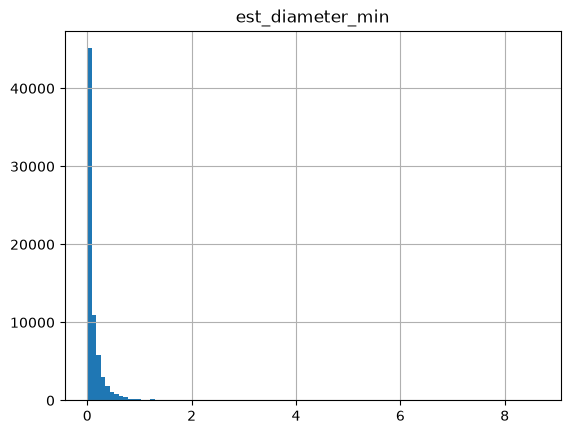

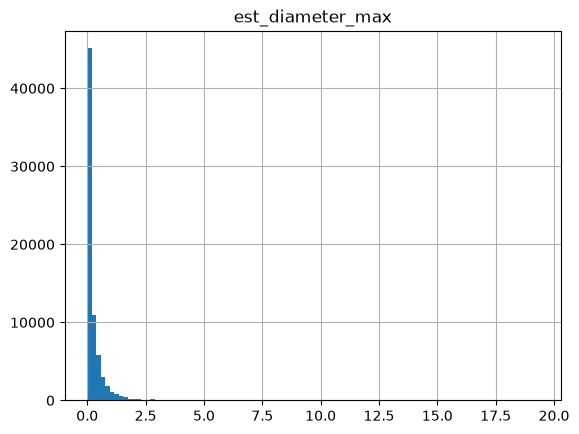

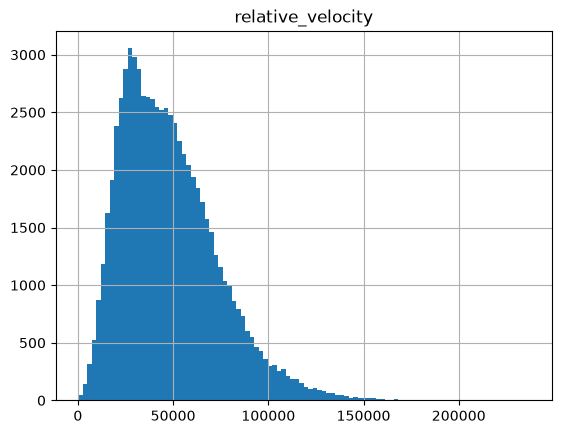

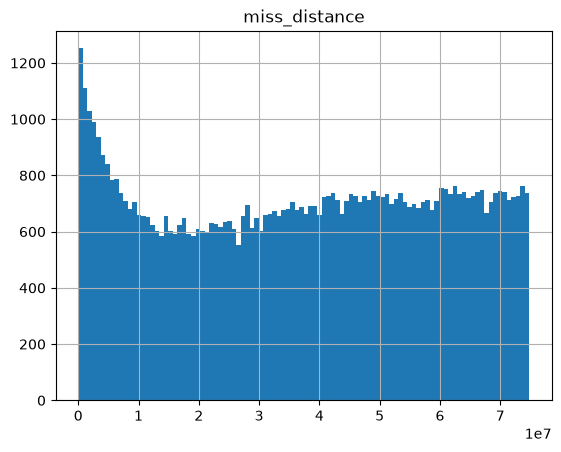

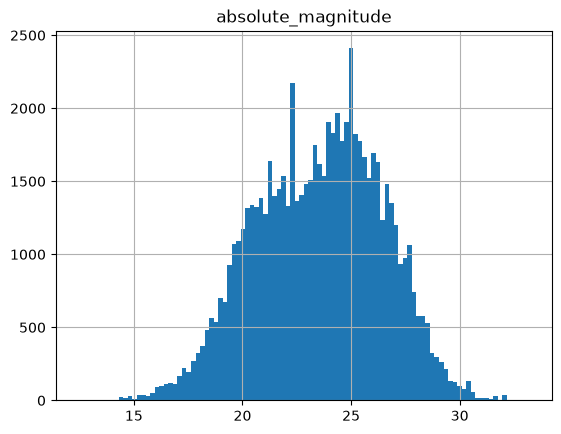

In [20]:
columns = ['est_diameter_min', 'est_diameter_max', 'relative_velocity', 'miss_distance', 'absolute_magnitude']

for column in columns:
    train.hist(column, bins=100)

Некоторые выводы из гистрограм:
- Распределения диаметров имеют очень сильную ассиметрию, подавляющее большинство объектов очень маленькие
- Огромное количество объектов зафиксировано на минимальном расстоянии от Земли
- **miss_distance** имеет почти равномерное распределение
- Есть четкий диапазон обычных скоростей и редкие сверхбыстрые объекты

Рассмотрим поближе гистограму диаматеров

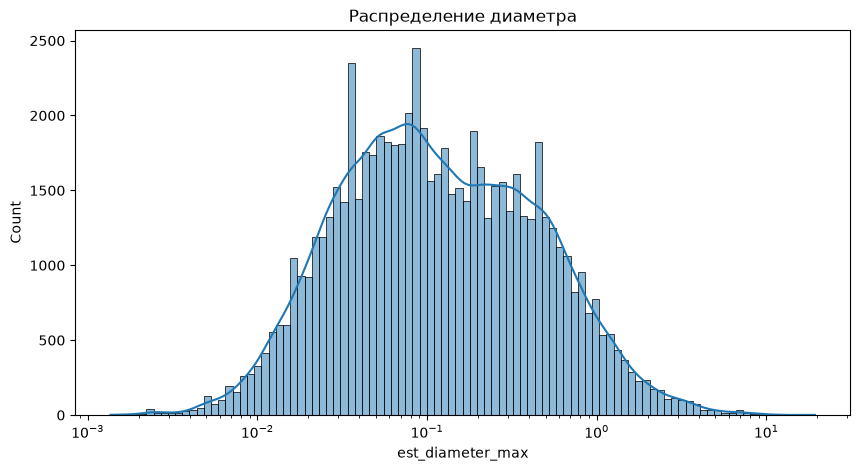

In [21]:
plt.figure(figsize=(10, 5))
# Логарифмируем масштаб оси х
sns.histplot(train['est_diameter_max'], kde=True, log_scale=True)
plt.title('Распределение диаметра')
plt.show()

Логарифмируем масштаб по оси х для того чтобы нагляднее посмотреть на распределение. Можно увидеть что оно бимодальное

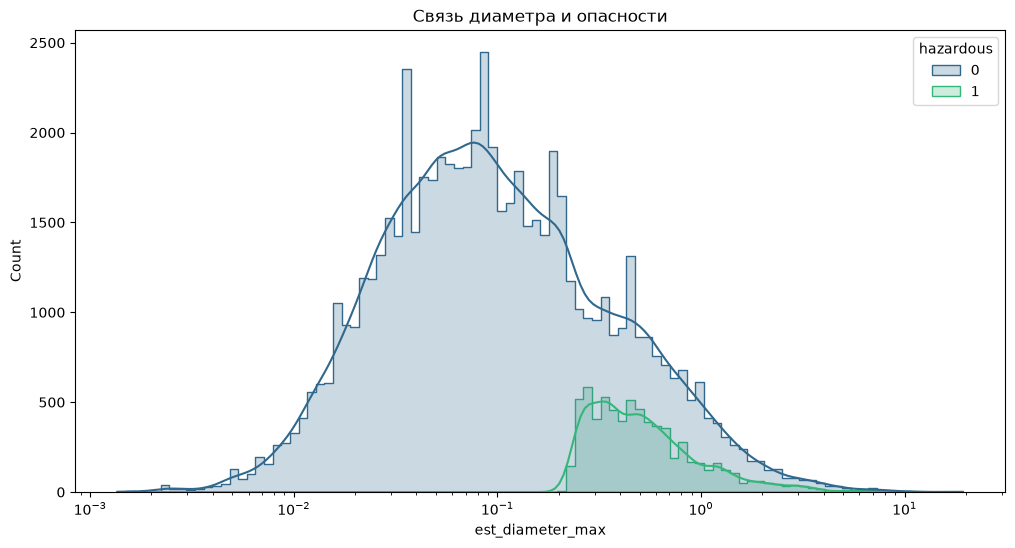

In [22]:
plt.figure(figsize=(12, 6))
# Добавляем hue='hazardous'
sns.histplot(data=train, x='est_diameter_max', hue='hazardous', 
             kde=True, log_scale=True, palette='viridis', element='step')
plt.title('Связь диаметра и опасности')
plt.show()

Можно увидеть, что зеленая область (опасные объекты) начинается очень резко, это значит что объекты меньше примерно 140 метров практически никогда не помечаются как опасные, значит если диаметр меньше этого порога, шанс на опасность объекта стремится к нулю.

Есть большие астероиды, которые не опасны, значит нужно посмотреть на признаки **miss_distance** и **relative_velocity**


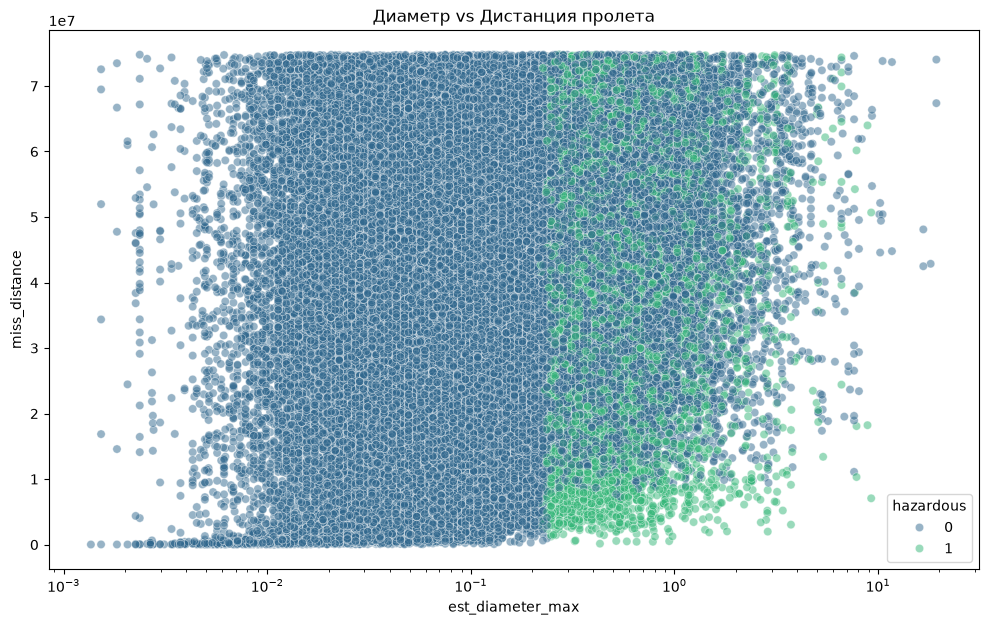

In [23]:
plt.figure(figsize=(12, 7))
sns.scatterplot(data=train, x='est_diameter_max', y='miss_distance', 
                hue='hazardous', alpha=0.5, palette='viridis')
plt.xscale('log') # Оставляем логарифмическую шкалу для диаметра
plt.title('Диаметр vs Дистанция пролета')
plt.show()

Видно четкую границу по оси X (диаметр), что значит что размер необходимое, но не достаточное условние опасности. 

Дистанция пролета тоже имеет корреляцию с опасностью (чем ближе тем опаснее), однако не такую сильную как размер

Выведем тепловую карту (Пирсон)

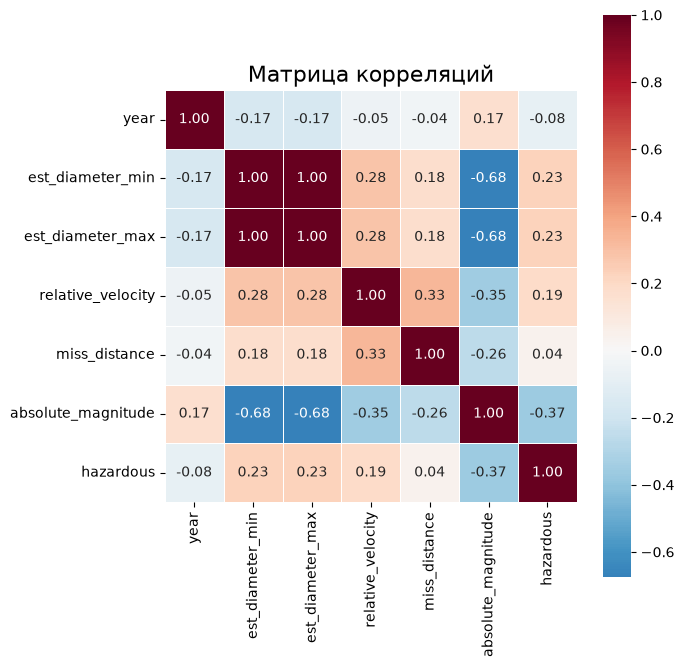

In [24]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
df_numeric = train[numeric_cols]

plt.figure(figsize=(7, 7))
correlation_matrix = df_numeric.corr(method='pearson')
sns.heatmap(correlation_matrix, 
            annot=True,  # показать значения
            fmt='.2f',   # формат чисел
            cmap='RdBu_r',  # цветовая схема
            center=0,    # центр в 0
            square=True,  # квадратные ячейки
            linewidths=0.5)  # линии между ячейками
plt.title('Матрица корреляций', fontsize=16)
plt.tight_layout()
plt.show()

Так как корреляция **est_diameter_min** и **est_diameter_max** равна 1, это по сути означает, что это один и тот же признак, поэтому целесообразно будет оставить только один из них. Если мы хотим понять, насколько опасен объект, нам важнее знать его максимально возможный размер, чтобы оценить потенциальную энергию удара, поэтому оставим только **est_diameter_max**, а **est_diameter_min** удалим

In [25]:
train = train.drop(columns='est_diameter_min')
test = test.drop(columns='est_diameter_min')
train

,year,est_diameter_max,relative_velocity,miss_distance,absolute_magnitude,hazardous
0,2011,0.035813,56014.078517,1.024333e+06,26.10,0
1,2016,0.124177,55257.544508,6.538636e+07,23.40,0
2,2013,0.043057,41531.404722,1.260796e+07,25.70,0
3,2007,0.103286,18933.875801,2.847083e+07,23.80,0
4,2018,0.259442,43184.402732,3.418417e+07,21.80,0
...,...,...,...,...,...,...
70838,2021,0.039268,23264.740825,1.635007e+06,25.90,0
70839,2018,0.247765,24802.519406,3.351901e+07,21.90,0
70840,2016,0.078350,116288.999548,5.471396e+07,24.40,0
70841,2014,0.098637,45763.317060,2.694877e+07,23.90,0


Снова выведем тепловую карту (Пирсон)

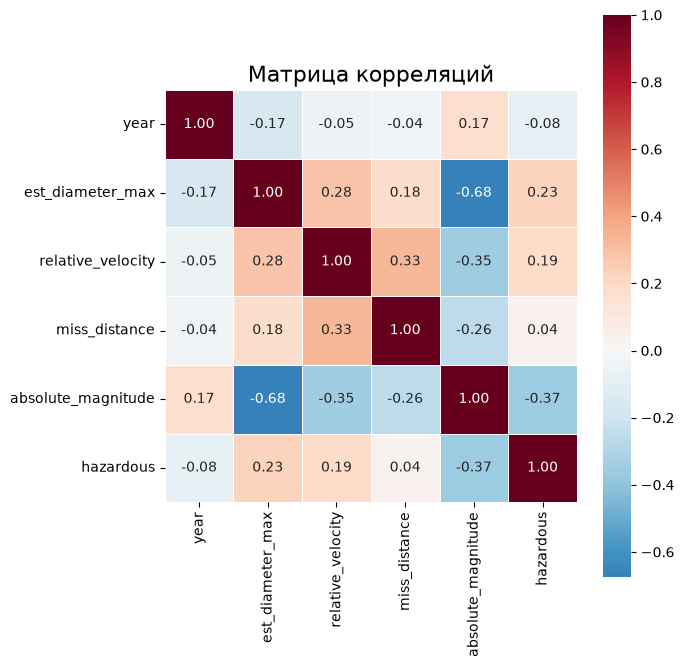

In [26]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
df_numeric = train[numeric_cols]

plt.figure(figsize=(7, 7))
correlation_matrix = df_numeric.corr(method='pearson')
sns.heatmap(correlation_matrix, 
            annot=True,  # показать значения
            fmt='.2f',   # формат чисел
            cmap='RdBu_r',  # цветовая схема
            center=0,    # центр в 0
            square=True,  # квадратные ячейки
            linewidths=0.5)  # линии между ячейками
plt.title('Матрица корреляций', fontsize=16)
plt.tight_layout()
plt.show()

У признака **absolute_magnitude** самая высокая корреляция с целевым признаком **hazardous**, за ним идет **est_diameter_max** с меньшей корреляцией, после них **relative_velocity** с еще меньшей корреляцией, при этом **miss_distance** почти не имеет корреляцию с целевым признаком, так же как и **year**

Для наглядности выведем тепловую карту (Спирмен)

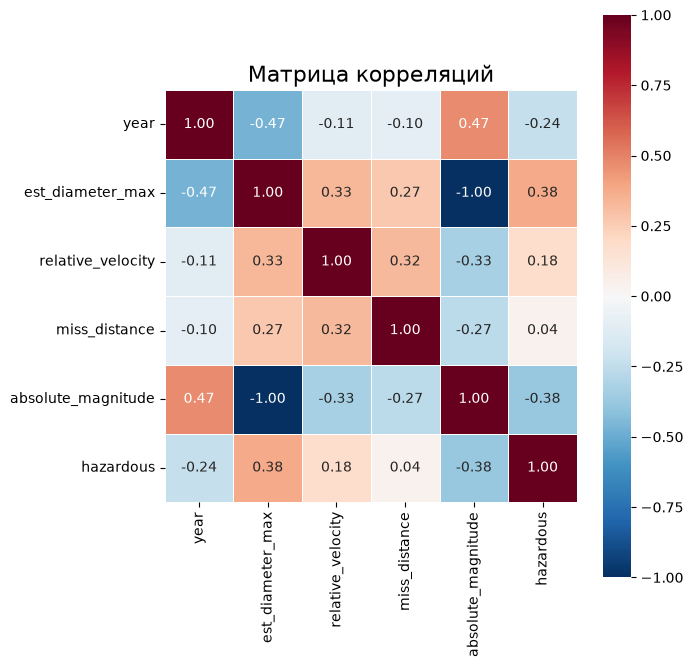

In [27]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
df_numeric = train[numeric_cols]

plt.figure(figsize=(7, 7))
correlation_matrix = df_numeric.corr(method='spearman')
sns.heatmap(correlation_matrix, 
            annot=True,  # показать значения
            fmt='.2f',   # формат чисел
            cmap='RdBu_r',  # цветовая схема
            center=0,    # центр в 0
            square=True,  # квадратные ячейки
            linewidths=0.5)  # линии между ячейками
plt.title('Матрица корреляций', fontsize=16)
plt.tight_layout()
plt.show()

Теперь можно наблюдать, что **year** все таки коррелирует с целевым признаком, **est_diameter_max** коррелирует сильнее.


Выводы:
- У **absolute_magnitude** и **est_diameter_max** самые высокие модули корреляции с **hazardous**
- **est_diameter_max** и **absolute_magnitude** один и тот же признак
-  Корреляция между **year** и **est_diameter_max** довольно большая

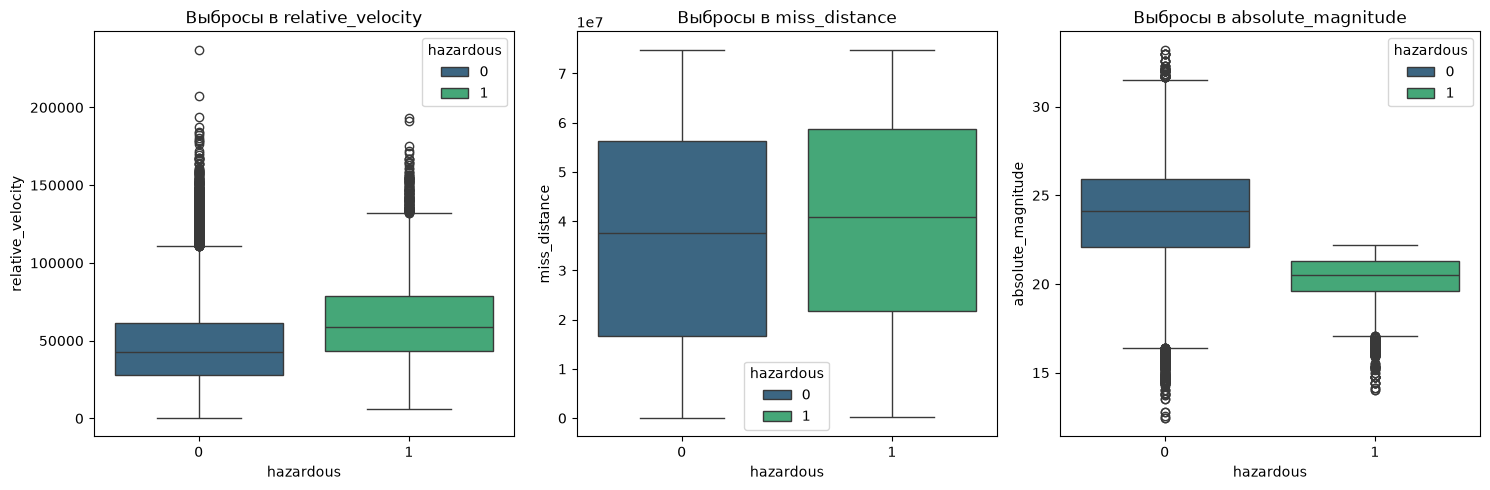

In [28]:
# Смотрим выбросы по скорости и дистанции
cols_to_check = ['relative_velocity', 'miss_distance', 'absolute_magnitude']

plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_check, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(data=train, y=col, x='hazardous', hue='hazardous', palette='viridis')
    plt.title(f'Выбросы в {col}')
plt.tight_layout()
plt.show()

Из ящиков с усами можно сделать следующие выводы:
- У **relative_velocity** большое количество выбросов в мажоритарном классе
- У **miss_distance** почти нет выбросов, что и следовало ожидать из гистрограммы
- У **absolute_magnitude** есть опасные маленькие астероиды и большие безопасные астероиды - выбросы, которые будут важны, так что их нельзя удалять.

Приравняем экстремальные выбросы к 99-ому процентилю у **relative_velocity**. Процентиль считаем **по train** и тем же порогом обрезаем test

In [29]:
limit = train['relative_velocity'].quantile(0.99)

# доля строк, которые будут обрезаны (считаем до обрезки)
clipped_train = (train['relative_velocity'] > limit).mean() * 100
clipped_test = (test['relative_velocity'] > limit).mean() * 100

train['relative_velocity'] = train['relative_velocity'].clip(upper=limit)
test['relative_velocity'] = test['relative_velocity'].clip(upper=limit)

limit, clipped_train, clipped_test

(np.float64(123956.34346459179),
 np.float64(1.000804596078653),
 np.float64(0.8083206150019784))

Примерно у 1% строк **relative_velocity** приравнен к 99-ому процентилю train

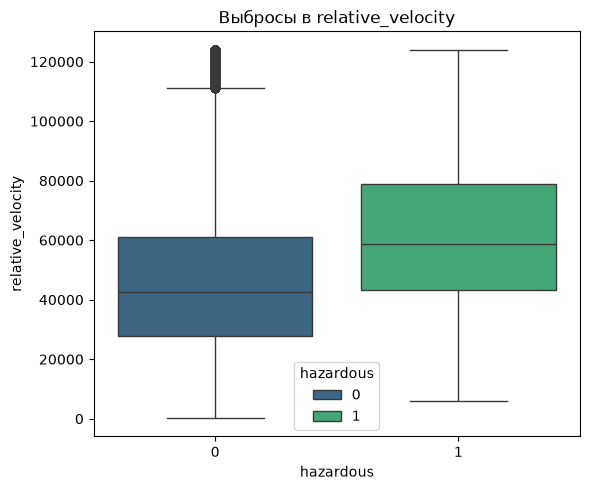

In [30]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=train, y='relative_velocity', x='hazardous', hue='hazardous', palette='viridis')
plt.title(f'Выбросы в relative_velocity')
plt.tight_layout()
plt.show()

In [31]:
train.to_csv('data/asteroids_train.csv', index=False)
test.to_csv('data/asteroids_test.csv', index=False)
train.shape, test.shape

((70843, 6), (17691, 6))

# Общие выводы:
Этот проект был направлен на изучение данных о характеристиках астероидов и определение ключевых факторов, влияющих на классификацию объекта как потенциально опасного. В ходе работы была проведена предобработка, заполнение пропусков и EDA.

Заполнение пропусков и работа с данными:
- Разделение на train и test выполнено до обработки данных, по объектам (все пролёты одного астероида попадают в одну выборку) с сохранением доли опасных объектов. Все пороги и решения принимались только по train.
- Строки с пропусками удалены — это менее 3% данных и опасных объектов.
- Из столбца name был извлечен год обнаружения объекта для анализа временных зависимостей.
- Устранена избыточность данных: из двух идентичных признаков размера (min_diameter, max_diameter) для обучения был выбран один — max_diameter, также был убран id базы данных.

Обработка выбросов:
- Для устранения влияния экстремально высоких скоростей в мажоритарном классе применен метод клиппинга по 99-му перцентилю. Это позволило сгладить распределение скорости без удаления строк.
- Выбросы в классе опасных объектов были намеренно сохранены, так как они представляют собой редкие, но критически важные физические аномалии.

Изучение факторов опасности:
- Ключевыми факторами, влияющими на классификацию, оказались размер, магнитуда и скорость. Дистанция пролета в конкретный момент времени показала слабую связь с итоговой меткой опасности.
- Размер (Absolute Magnitude): Выявлен четкий порог опасности. Объекты с магнитудой выше определенного значения (мелкие объекты) практически никогда не признаются опасными. Визуализация в логарифмической шкале подтвердила бимодальность распределения.
- Скорость (Relative Velocity): Опасные объекты в среднем обладают более высокой скоростью. Скорость выступает допольнительным признаком указывающим на опасность для крупных тел.
- Дистанция (Miss Distance): Классификация объекта зависит скорее всего от его орбиты в целом, а не от дистанции, зафиксированного в датасете, так как корреляция с опасностью практически отсутвует.

Дисбаланс классов:
- В данных наблюдается умеренный дисбаланс (соотношение 1:9 в пользу неопасных объектов), что потребует отдельного внимания на следующих этапах.